In [ ]:
# ---------------------------------------------------------------------------
# Import Libraries and Reproducibility setup
# ---------------------------------------------------------------------------
import os
import sys
import numpy
import scipy
import matplotlib
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm, pearsonr, skew
from scipy.optimize import minimize


SEED = 42                                                 # Random seed 
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ---------------------------------------------------------------------------
# Load data
# ---------------------------------------------------------------------------
X = np.load('..\Function_2_Data\Week_10_Data/F2_Week_10_inputs.npy')
y = np.load('..\Function_2_Data\Week_10_Data/F2_Week_10_outputs.npy')

n, d = X.shape
n_initial = 10
print(f"n_samples={n} (initial=0:{n_initial}, queried={n_initial}:{n}), n_dims={d}")

n_samples=19 (initial=0:10, queried=10:19), n_dims=2


Raw y:          mean=0.3628, std=0.2456, min=-0.0656, max=0.6951
Standardized y: mean=-0.0000, std=1.0000


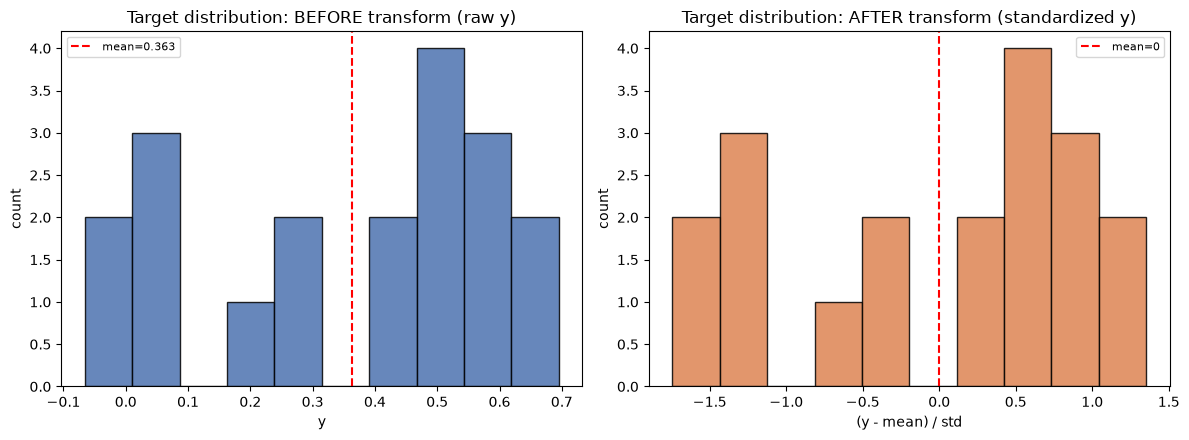

In [ ]:
# ---------------------------------------------------------------------------
# nput transformation (unchanged)
# ---------------------------------------------------------------------------
# Inputs already live in [0,1] x [0,1].
bounds = np.array([[0.0, 1.0], [0.0, 1.0]])

# ---------------------------------------------------------------------------
# Output transformation: standardize y
# ---------------------------------------------------------------------------
y_mean, y_std = y.mean(), y.std()
y_scaled = (y - y_mean) / y_std

def unscale_y(y_s):
    return y_s * y_std + y_mean      # Map standardized y back to original units.

fig_dist, axes_dist = plt.subplots(1, 2, figsize=(12, 4.5))

axes_dist[0].hist(y, bins=10, color="#4C72B0", edgecolor="black", alpha=0.85)
axes_dist[0].axvline(y_mean, color="red", linestyle="--", linewidth=1.5, label=f"mean={y_mean:.3f}")
axes_dist[0].set_title("Target distribution: BEFORE transform (raw y)")
axes_dist[0].set_xlabel("y"); axes_dist[0].set_ylabel("count")
axes_dist[0].legend(fontsize=8)

axes_dist[1].hist(y_scaled, bins=10, color="#DD8452", edgecolor="black", alpha=0.85)
axes_dist[1].axvline(0.0, color="red", linestyle="--", linewidth=1.5, label="mean=0")
axes_dist[1].set_title("Target distribution: AFTER transform (standardized y)")
axes_dist[1].set_xlabel("(y - mean) / std"); axes_dist[1].set_ylabel("count")
axes_dist[1].legend(fontsize=8)

plt.tight_layout()
print(f"Raw y:          mean={y_mean:.4f}, std={y_std:.4f}, min={y.min():.4f}, max={y.max():.4f}")
print(f"Standardized y: mean={y_scaled.mean():.4f}, std={y_scaled.std():.4f}")


In [ ]:
# ---------------------------------------------------------------------------
# Surrogate model
# ---------------------------------------------------------------------------

LS_BOUNDS = (0.05, 1.0)
NOISE_BOUNDS = (1e-8, 2e-1)
kernel = (
    ConstantKernel(1.0, constant_value_bounds=(1e-3, 1e3))
    * Matern(length_scale=[0.3, 0.3], length_scale_bounds=LS_BOUNDS, nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=NOISE_BOUNDS)
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=20,
    normalize_y=False,
    random_state=SEED,
)
gp.fit(X, y_scaled)

print("\nFitted kernel:", gp.kernel_)
print("Log-marginal-likelihood:", gp.log_marginal_likelihood_value_)

length_scales = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
noise_var = gp.kernel_.k2.noise_level          # standardized units
print(f"Fitted noise std (original y units): {np.sqrt(noise_var) * y_std:.4f}")

# ---------------------------------------------------------------------------
# Leave-one-out CV check.
# ---------------------------------------------------------------------------
loo_mu = np.empty(n)
for i in range(n):
    keep = np.arange(n) != i
    gp_i = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None).fit(X[keep], y_scaled[keep])
    loo_mu[i] = gp_i.predict(X[i:i + 1])[0]
loo_rmse = np.sqrt(np.mean((y_scaled - loo_mu) ** 2))
print(f"Leave-one-out RMSE / std(y): {loo_rmse:.3f}")


mu_train = gp.predict(X)
inc_idx = int(np.argmax(mu_train))
y_best = mu_train[inc_idx]
obs_idx = int(np.argmax(y))
print(f"\nBest observed y:        x={X[obs_idx]}, y={y[obs_idx]:.4f}")
print(f"Incumbent (post. mean): x={X[inc_idx]}, mean={unscale_y(y_best):.4f}  <-- used as EI baseline")



Fitted kernel: 0.991**2 * Matern(length_scale=[0.05, 1], nu=2.5) + WhiteKernel(noise_level=0.054)
Log-marginal-likelihood: -17.848298250680507
Fitted noise std (original y units): 0.0571
Leave-one-out RMSE / std(y): 0.636

Best observed y:        x=[0.704881 0.      ], y=0.6951
Incumbent (post. mean): x=[0.704881 0.      ], mean=0.6443  <-- used as EI baseline


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [ ]:
# ---------------------------------------------------------------------------
# Acquisition function: noise-aware Expected Improvement
# ---------------------------------------------------------------------------
def latent_posterior(X_cand, gp):
    mu, sigma = gp.predict(X_cand, return_std=True)
    sigma_f = np.sqrt(np.maximum(sigma ** 2 - noise_var, 1e-18))
    return mu, sigma_f

def expected_improvement(X_cand, gp, y_best, xi):
    mu, sigma = latent_posterior(X_cand, gp)
    imp = mu - y_best - xi
    z = imp / sigma
    return imp * norm.cdf(z) + sigma * norm.pdf(z)

def ei_local_maxima(ei_grid, gx, gy, rel_threshold=0.05, min_sep=0.05):
    padded = np.pad(ei_grid, 1, constant_values=-np.inf)
    neigh = np.max([padded[1 + di:padded.shape[0] - 1 + di, 1 + dj:padded.shape[1] - 1 + dj]
                    for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0)], axis=0)
    rows, cols = np.where((ei_grid > neigh) & (ei_grid >= rel_threshold * ei_grid.max()))
    cands = sorted(((ei_grid[r, c], np.array([gx[c], gy[r]])) for r, c in zip(rows, cols)),
                   key=lambda t: -t[0])
    distinct = []
    for ei, x in cands:
        if all(np.linalg.norm(x - dx) > min_sep for _, dx in distinct):
            distinct.append((ei, x))
    return distinct

def polish(x0, gp, y_best, xi, bounds):
    """Refine a grid maximum with one bounded L-BFGS-B run started on it."""
    res = minimize(lambda x: -expected_improvement(x.reshape(1, -1), gp, y_best, xi)[0],
                   x0, bounds=bounds, method="L-BFGS-B")
    return (res.x, -res.fun) if -res.fun >= expected_improvement(x0.reshape(1, -1), gp, y_best, xi)[0] else (x0, None)


In [ ]:
# ---------------------------------------------------------------------------
# Suggestions for the next query
# ---------------------------------------------------------------------------
XI = 0.01

grid_n = 401
gx = np.linspace(0, 1, grid_n)
gy = np.linspace(0, 1, grid_n)
GX, GY = np.meshgrid(gx, gy)
grid_pts = np.column_stack([GX.ravel(), GY.ravel()])

mu_grid, std_grid = latent_posterior(grid_pts, gp)
ei_grid = expected_improvement(grid_pts, gp, y_best, xi=XI).reshape(grid_n, grid_n)

suggestions = []
for rank, (ei, x) in enumerate(ei_local_maxima(ei_grid, gx, gy)[:4], start=1):
    x_p, ei_p = polish(x, gp, y_best, XI, bounds)
    mu_s, std_s = latent_posterior(x_p.reshape(1, -1), gp)
    suggestions.append({"label": f"EI local max #{rank}", "x": x_p,
                        "pred_mean": unscale_y(mu_s[0]), "pred_std": std_s[0] * y_std,
                        "ei": ei if ei_p is None else ei_p})

print(f"\nEI local maxima on a {grid_n}x{grid_n} grid (xi={XI}), best first:")
for s in suggestions:
    print(f"  [{s['label']}]  x=({s['x'][0]:.6f}, {s['x'][1]:.6f})  "
          f"pred_mean={s['pred_mean']:.4f}  latent_std={s['pred_std']:.4f}  EI={s['ei']:.5f}")

x_next = suggestions[0]["x"]   # exploit choice: the global EI maximum
PROBE_POINT = np.array([0.69, 0.45])
mu_c, std_c = latent_posterior(PROBE_POINT.reshape(1, -1), gp)


EI local maxima on a 401x401 grid (xi=0.01), best first:
  [EI local max #1]  x=(0.692287, 0.000000)  pred_mean=0.6722  latent_std=0.0565  EI=0.15241
  [EI local max #2]  x=(0.962122, 0.514997)  pred_mean=0.3841  latent_std=0.2372  EI=0.06528
  [EI local max #3]  x=(0.960775, 0.382509)  pred_mean=0.3841  latent_std=0.2372  EI=0.06527
  [EI local max #4]  x=(0.000000, 1.000000)  pred_mean=0.3502  latent_std=0.2434  EI=0.05349


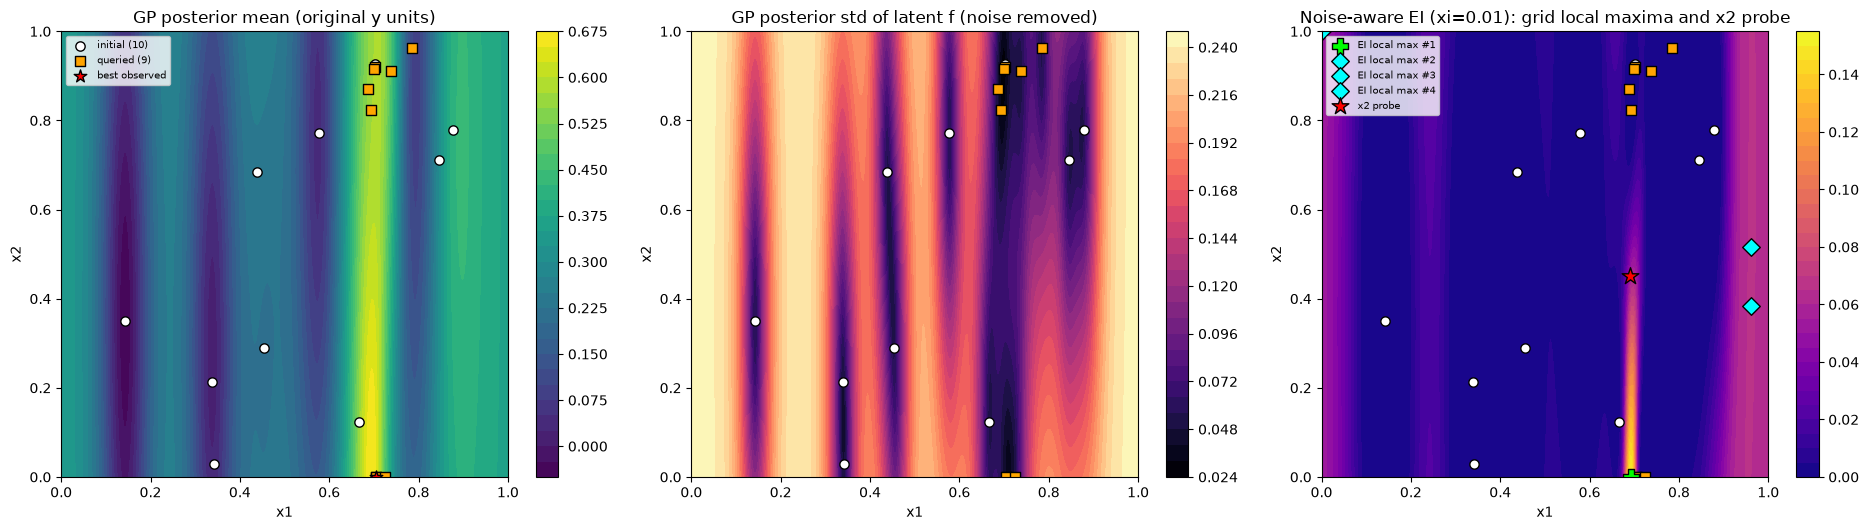

In [ ]:
# ---------------------------------------------------------------------------
# Plots: GP posterior mean / std / EI 
# ---------------------------------------------------------------------------
mu_grid_orig = unscale_y(mu_grid).reshape(grid_n, grid_n)
std_grid_orig = (std_grid * y_std).reshape(grid_n, grid_n)

def scatter_data(ax, with_labels=False):
    ax.scatter(X[:n_initial, 0], X[:n_initial, 1], c="white", edgecolor="black", s=45,
               label="initial (10)" if with_labels else None)
    ax.scatter(X[n_initial:, 0], X[n_initial:, 1], c="orange", edgecolor="black", s=60, marker="s",
               label="queried (9)" if with_labels else None)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4))

im0 = axes[0].contourf(GX, GY, mu_grid_orig, levels=30, cmap="viridis")
scatter_data(axes[0], with_labels=True)
axes[0].scatter(*X[obs_idx], c="red", edgecolor="black", s=90, marker="*", label="best observed")
axes[0].set_title("GP posterior mean (original y units)")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
fig.colorbar(im0, ax=axes[0])
axes[0].legend(loc="upper left", fontsize=7)

im1 = axes[1].contourf(GX, GY, std_grid_orig, levels=30, cmap="magma")
scatter_data(axes[1])
axes[1].set_title("GP posterior std of latent f (noise removed)")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].contourf(GX, GY, ei_grid, levels=30, cmap="plasma")
scatter_data(axes[2])
marker_styles = [("lime", "P", 130), ("cyan", "D", 80), ("cyan", "D", 80), ("cyan", "D", 80)]
for s, (color, shape, size) in zip(suggestions, marker_styles):
    axes[2].scatter(*s["x"], c=color, edgecolor="black", s=size, marker=shape, label=s["label"])
axes[2].scatter(*PROBE_POINT, c="red", edgecolor="black", s=160, marker="*", label="x2 probe")
axes[2].set_title(f"Noise-aware EI (xi={XI}): grid local maxima and x2 probe")
axes[2].set_xlabel("x1"); axes[2].set_ylabel("x2")
fig.colorbar(im2, ax=axes[2])
axes[2].legend(loc="upper left", fontsize=7)

plt.tight_layout()


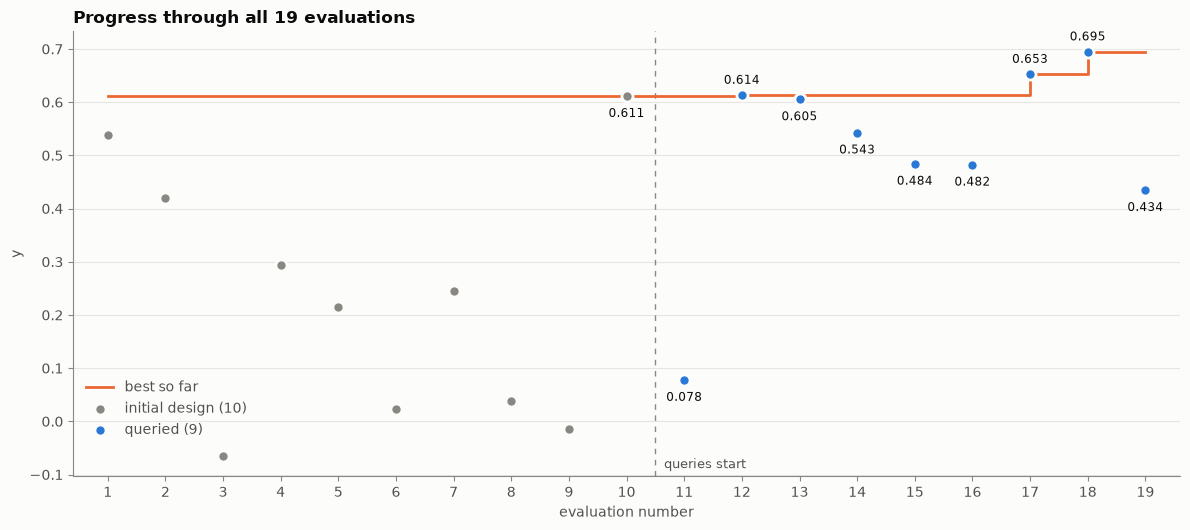

In [ ]:
# ---------------------------------------------------------------------------
# Progress through all evaluations Plot
# ---------------------------------------------------------------------------

eval_idx = np.arange(1, n + 1)
best_so_far = np.maximum.accumulate(np.r_[np.full(n_initial, y[:n_initial].max()), y[n_initial:]])
is_initial = eval_idx <= n_initial

SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
with plt.rc_context({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": MUTED,
                     "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True}):
    fig_p, ax_p = plt.subplots(figsize=(12, 5.4))
    ax_p.grid(axis="y", color=GRID, linewidth=0.8)
    ax_p.axvline(n_initial + 0.5, color=MUTED, linewidth=1, linestyle=(0, (4, 4)))
    ax_p.step(eval_idx, best_so_far, where="post", color="#eb6834", linewidth=2, label="best so far", zorder=2)
    ax_p.scatter(eval_idx[is_initial], y[is_initial], s=64, color=MUTED, edgecolor=SURFACE, linewidth=2,
                 label=f"initial design ({n_initial})", zorder=3)
    ax_p.scatter(eval_idx[~is_initial], y[~is_initial], s=64, color="#2a78d6", edgecolor=SURFACE, linewidth=2,
                 label=f"queried ({n - n_initial})", zorder=3)
    for i in np.where(~is_initial)[0]:
        # labels go above points that set a new best, so they clear the step line
        dy = 8 if y[i] >= best_so_far[i] else -15
        ax_p.annotate(f"{y[i]:.3f}", (eval_idx[i], y[i]), xytext=(0, dy), textcoords="offset points",
                      ha="center", fontsize=8.5, color=INK)
    i0 = int(np.argmax(y[:n_initial]))
    ax_p.annotate(f"{y[i0]:.3f}", (eval_idx[i0], y[i0]), xytext=(0, -15), textcoords="offset points",
                  ha="center", fontsize=8.5, color=INK)
    ax_p.text(n_initial + 0.65, ax_p.get_ylim()[0] + 0.01, "queries start", color=INK2, fontsize=9, va="bottom")
    ax_p.set_xticks(eval_idx)
    ax_p.set_xlim(0.4, n + 0.6)
    ax_p.set_xlabel("evaluation number")
    ax_p.set_ylabel("y")
    ax_p.set_title("Progress through all 19 evaluations", loc="left", fontweight="bold", color=INK)
    ax_p.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.06), labelcolor=INK2)
    fig_p.tight_layout()